# Presentasi UAS Machine Learning: Prediksi Risiko Stroke pada Korpus Biomarker Klinis (37.940 Pasien Bersih)

**Mata Kuliah:** Machine Learning (Kelas C)  
**Dosen Pengampu:** Bapak I Ketut Adi Purnawan, S.T., M.Kom.  

**Kelompok 3:**
- Deliana Br Manalu (2305551036)
- Ravi Arnan Irianto (2305551076)
- Ezza Putra Wibawa (2305551144)
- Devin (2305551173)

---

## Peta Alur Proses di Notebook (End-to-End Colab Pipeline)

Notebook ini dirancang sebagai **kode presentasi utama UAS** yang berjalan runtut dari awal hingga akhir di Google Colab:
1. **Pemuatan & Audit Data Mentah (50.000 baris, 40 kolom)**: Mengecek tipe data, statistik deskriptif, *missing values*, dan duplikasi.
2. **Pembersihan Data & Eliminasi *Target Leakage***: Menghapus baris kosong (`dropna`) dan duplikasi (`drop_duplicates`) sehingga tersisa **37.940 pasien bersih**, serta membuang 4 kolom pasca-diagnosis.
3. **EDA Terarah**: Menganalisis profil biomarker utama dan matriks korelasi terhadap target risiko stroke.
4. **Pembagian Data Stratified (70% Latih / 15% Validasi / 15% Uji)**: Memastikan proporsi kelas konsisten dan menjaga data validasi/uji tetap terisolasi.
5. **Analisis *Feature Importance* & Seleksi Fitur (Sebelum Pemodelan)**: Mengukur kontribusi seluruh 35 fitur asli pada Data Latih (bebas kebocoran) dan menyaring **26 fitur berkontribusi tinggi (>= 0,5%)** sebagai dataset masukan model.
6. **Preprocessing Berbeda Tiap Model pada Fitur Terpilih**:
   - **Logistic Regression**: `StandardScaler` + `OneHotEncoder(drop='first')` (`27` kolom)
   - **Random Forest**: Skala asli (`passthrough`) + `OrdinalEncoder` (`26` kolom)
   - **Gradient Boosting**: Skala asli (`passthrough`) + `OneHotEncoder` penuh (`42` kolom)
7. **Baseline vs Improvement + Confusion Matrix Setiap Model**: Membandingkan performa parameter bawaan (`t = 0,50`) melawan model teroptimasi (*hyperparameter tuning*, pembobotan kelas RF, *threshold tuning* pada Validation Set, plus *Ensemble Soft Voting*), lengkap dengan Confusion Matrix masing-masing serta kurva ROC & PR.
8. **Validasi Berlapis**: 5-Fold Stratified Cross-Validation (pada ambang optimal), Bootstrap 95% Confidence Interval, dan Learning Curve.

## 1. Persiapan Lingkungan & Pustaka

In [ ]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")

plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

SEED = 42
np.random.seed(SEED)

ASSET_DIR = Path("assets/evaluasi_15")
if Path("..").resolve().name == "machine-learning" or Path("../datasets").exists():
    ASSET_DIR = Path("../assets/evaluasi_15")
ASSET_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACT_DIR = Path("artifacts")
if Path("../artifacts").exists():
    ARTIFACT_DIR = Path("../artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Pustaka siap. Direktori aset:", ASSET_DIR.resolve())

Pustaka siap. Direktori aset: /content/assets/evaluasi_15


## 2. Pemuatan Seluruh Dataset & Analisis Kualitas Data (Missing Value & Duplikasi)

Dataset yang digunakan adalah `stroke_risk_prediction_dataset.csv` dengan **50.000 catatan pasien dan 40 atribut**. Seluruh baris dimuat utuh untuk diaudit terlebih dahulu sebelum pembersihan.

In [ ]:
GITHUB_RAW_URL = (
    "https://raw.githubusercontent.com/ravi-arnan/machine-learning/main/"
    "datasets/stroke_risk_prediction_dataset.csv"
)

candidate_paths = [
    Path("datasets/stroke_risk_prediction_dataset.csv"),
    Path("../datasets/stroke_risk_prediction_dataset.csv"),
    Path("stroke_risk_prediction_dataset.csv"),
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is not None:
    print(f"Memuat dataset lokal dari: {data_path.resolve()}")
    df_raw = pd.read_csv(data_path)
else:
    print(f"File lokal tidak ditemukan, mengunduh dari GitHub:\n{GITHUB_RAW_URL}")
    df_raw = pd.read_csv(GITHUB_RAW_URL)

print(f"\nDimensi Dataset Mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
display(df_raw.head(5))
print("\nStatistik Deskriptif Atribut Numerik (Data Mentah):")
display(df_raw.select_dtypes(include=["number"]).drop(columns=["Patient_ID"]).describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

File lokal tidak ditemukan, mengunduh dari GitHub:
https://raw.githubusercontent.com/ravi-arnan/machine-learning/main/datasets/stroke_risk_prediction_dataset.csv



Dimensi Dataset Mentah: 50,000 baris x 40 kolom


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
0,1,80.0,Male,China,145.2,69.3,32.9,112,82,109,...,Excellent,NaN,79.0,Retired,Urban,High,47,Exercise Regularly,Yes,Moderate
1,2,37.0,Female,United Kingdom,188.6,110.8,31.1,137,76,59,...,Average,0.6,48.0,Student,Rural,Medium,40,Improve Diet Quality,Yes,Moderate
2,3,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,...,Poor,1.7,114.0,Private,Rural,Medium,76,Monitor Blood Glucose Daily,Yes,High
3,4,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,...,Poor,1.5,101.0,Retired,Rural,Low,40,Exercise Regularly,Yes,Moderate
4,5,52.0,Female,United States,162.8,103.6,39.1,115,60,70,...,Average,7.1,55.0,Government,Rural,Medium,38,Monitor Blood Pressure,Yes,Moderate



Statistik Deskriptif Atribut Numerik (Data Mentah):


,count,mean,std,min,50%,max
Age,49781.0,53.90,21.07,18.0,54.0,90.0
Height_cm,48475.0,170.13,14.48,145.0,170.1,195.0
Weight_kg,48477.0,87.51,24.57,45.0,87.5,130.0
BMI,50000.0,30.90,10.25,11.9,30.1,61.5
Blood_Pressure_Systolic,50000.0,135.06,20.53,100.0,135.0,170.0
Blood_Pressure_Diastolic,50000.0,84.84,14.69,60.0,85.0,110.0
Heart_Rate,50000.0,82.52,16.14,55.0,83.0,110.0
Blood_Glucose,49040.0,145.03,43.41,70.0,145.1,220.0
HbA1c,48994.0,7.49,1.73,4.5,7.5,10.5
Total_Cholesterol,48996.0,225.02,54.78,130.0,224.9,320.0


In [ ]:
# Audit Missing Values & Duplikasi pada Seluruh 50.000 Baris
na_per_col = df_raw.isna().sum()
na_df = pd.DataFrame({
    "Kolom": na_per_col.index,
    "Jumlah_Kosong": na_per_col.values,
    "Persentase (%)": (na_per_col.values / len(df_raw)) * 100,
})
na_nonzero = na_df[na_df["Jumlah_Kosong"] > 0].sort_values("Jumlah_Kosong", ascending=False)

rows_with_na = int(df_raw.isna().any(axis=1).sum())
dup_exact = int(df_raw.duplicated().sum())
dup_id = int(df_raw["Patient_ID"].duplicated().sum())
dup_features = int(df_raw.drop(columns=["Patient_ID"]).duplicated().sum())

print("=== RINGKASAN AUDIT KUALITAS DATA MENTAH ===")
print(f"Total baris awal                : {len(df_raw):,}")
print(f"Total sel kosong                : {int(df_raw.isna().sum().sum()):,} sel pada {len(na_nonzero)} kolom")
print(f"Baris yang memiliki data kosong : {rows_with_na:,} baris ({rows_with_na / len(df_raw) * 100:.2f}%)")
print(f"Duplikasi baris penuh           : {dup_exact:,}")
print(f"Duplikasi Patient_ID            : {dup_id:,}")
print(f"Duplikasi fitur (tanpa ID)      : {dup_features:,}")
print("\nRincian Kolom dengan Missing Values:")
display(na_nonzero.reset_index(drop=True))

=== RINGKASAN AUDIT KUALITAS DATA MENTAH ===
Total baris awal                : 50,000
Total sel kosong                : 13,522 sel pada 13 kolom
Baris yang memiliki data kosong : 12,060 baris (24.12%)
Duplikasi baris penuh           : 0
Duplikasi Patient_ID            : 0
Duplikasi fitur (tanpa ID)      : 0

Rincian Kolom dengan Missing Values:


,Kolom,Jumlah_Kosong,Persentase (%)
0,Height_cm,1525,3.050
1,Weight_kg,1523,3.046
2,Exercise_Hours_Per_Week,1054,2.108
3,Medication_Adherence,1051,2.102
4,Daily_Walking_Minutes,1051,2.102
5,LDL,1050,2.100
6,Triglycerides,1032,2.064
7,Sleep_Hours,1026,2.052
8,HDL,1021,2.042
9,HbA1c,1006,2.012


## 3. Pembersihan Data (`dropna` & `drop_duplicates`) dan Eliminasi *Target Leakage*

1. Menghapus 12.060 baris yang memiliki data kosong (`dropna`) agar seluruh data merupakan rekaman klinis riil tanpa imputasi buatan.
2. Memverifikasi bebas duplikasi (`drop_duplicates`), menyisakan **37.940 pasien bersih**.
3. Membuang 4 kolom *target leakage* (`Patient_ID`, `Stroke_Risk_Score`, `AI_Health_Recommendation`, `Doctor_Consultation_Needed`) dan merumuskan target biner `stroke_risk_high` (`High` = 1, `Moderate/Low` = 0).

=== HASIL PEMBERSIHAN DATA ===
Baris awal                     : 50,000
Baris setelah dropna()         : 37,940 (dibuang 12,060)
Baris setelah drop_duplicates(): 37,940 (dibuang 0)
Duplikasi fitur tanpa ID       : 0
Sisa missing value             : 0
Fitur prediktor valid awal     : 35 kolom (16 numerik, 19 kategorikal)
Distribusi Target (0 vs 1)     : 28,747 Non-High (75,77%) | 9,193 High Risk (24.23%)


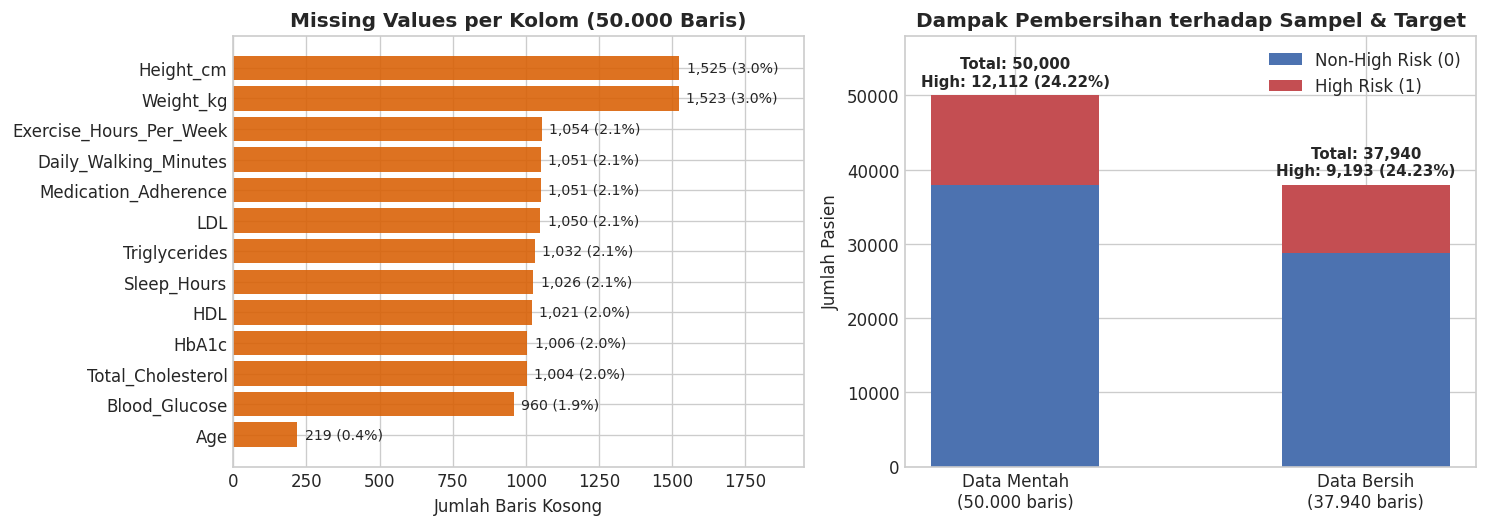

In [ ]:
# 1. Hapus baris dengan missing value dan duplikasi
df_no_na = df_raw.dropna().copy()
after_na = len(df_no_na)
df_clean = df_no_na.drop_duplicates().reset_index(drop=True)
after_dup = len(df_clean)
dup_feat_clean = int(df_clean.drop(columns=["Patient_ID"]).duplicated().sum())

# 2. Formulasi Target & Eliminasi Target Leakage
y = (df_clean["Stroke_Risk"] == "High").astype(int)
leak_cols = [
    "Patient_ID",
    "Stroke_Risk_Score",
    "AI_Health_Recommendation",
    "Doctor_Consultation_Needed",
    "Stroke_Risk",
]
X = df_clean.drop(columns=leak_cols).copy()

num_cols_all = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols_all = X.select_dtypes(exclude=["number"]).columns.tolist()

print("=== HASIL PEMBERSIHAN DATA ===")
print(f"Baris awal                     : {len(df_raw):,}")
print(f"Baris setelah dropna()         : {after_na:,} (dibuang {len(df_raw) - after_na:,})")
print(f"Baris setelah drop_duplicates(): {after_dup:,} (dibuang {after_na - after_dup:,})")
print(f"Duplikasi fitur tanpa ID       : {dup_feat_clean}")
print(f"Sisa missing value             : {int(X.isna().sum().sum())}")
print(f"Fitur prediktor valid awal     : {X.shape[1]} kolom ({len(num_cols_all)} numerik, {len(cat_cols_all)} kategorikal)")
print(f"Distribusi Target (0 vs 1)     : {(y == 0).sum():,} Non-High (75,77%) | {(y == 1).sum():,} High Risk ({y.mean()*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
na_plot = na_nonzero.sort_values("Jumlah_Kosong", ascending=True)
axes[0].barh(na_plot["Kolom"], na_plot["Jumlah_Kosong"], color="#d95f02", alpha=0.88)
axes[0].set_title("Missing Values per Kolom (50.000 Baris)", fontweight="bold")
axes[0].set_xlabel("Jumlah Baris Kosong")
for idx, val in enumerate(na_plot["Jumlah_Kosong"]):
    axes[0].text(val + 25, idx, f"{val:,} ({val/len(df_raw)*100:.1f}%)", va="center", fontsize=8.5)
axes[0].set_xlim(0, na_plot["Jumlah_Kosong"].max() * 1.28)

labels_stage = ["Data Mentah\n(50.000 baris)", "Data Bersih\n(37.940 baris)"]
high_counts = [int((df_raw["Stroke_Risk"] == "High").sum()), int((y == 1).sum())]
non_high_counts = [len(df_raw) - high_counts[0], len(df_clean) - high_counts[1]]

x_pos = np.arange(len(labels_stage))
axes[1].bar(x_pos, non_high_counts, width=0.48, label="Non-High Risk (0)", color="#4c72b0")
axes[1].bar(x_pos, high_counts, width=0.48, bottom=non_high_counts, label="High Risk (1)", color="#c44e52")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_stage, fontsize=10)
axes[1].set_ylabel("Jumlah Pasien")
axes[1].set_title("Dampak Pembersihan terhadap Sampel & Target", fontweight="bold")
axes[1].legend(loc="upper right")
for i in range(2):
    tot = non_high_counts[i] + high_counts[i]
    axes[1].text(i, tot + 900, f"Total: {tot:,}\nHigh: {high_counts[i]:,} ({high_counts[i]/tot*100:.2f}%)",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_ylim(0, 58000)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_01_audit_dan_pembersihan.png", dpi=150, bbox_inches="tight")
plt.show()

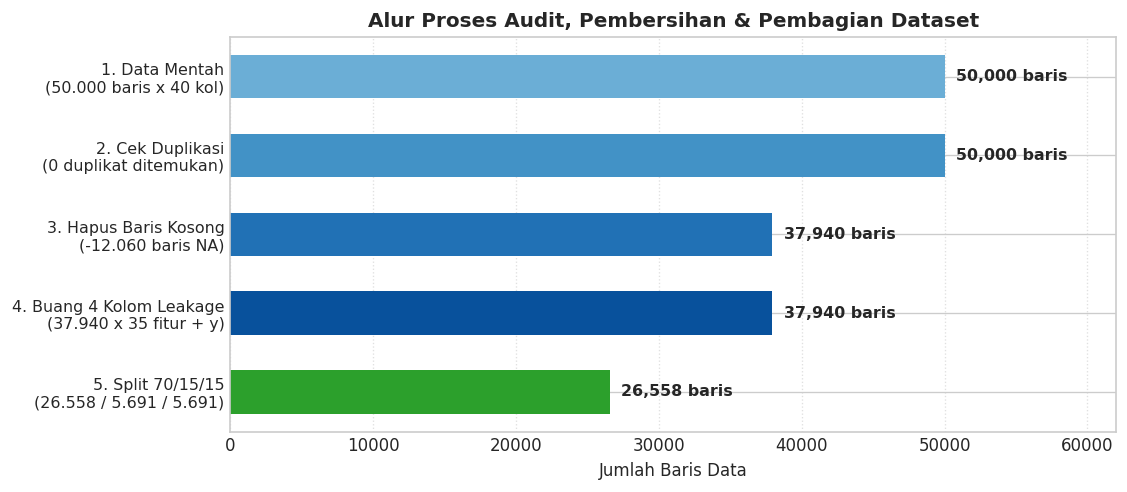

Contoh 5 Baris Data Bersih (35 Fitur Sebelum Seleksi Fitur):


,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Blood_Glucose,...,Heart_Disease,Previous_TIA,Atrial_Fibrillation,Chronic_Kidney_Disease,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure
0,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,196.4,...,No,No,No,No,Poor,1.7,114.0,Private,Rural,Medium
1,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,209.1,...,No,No,No,Yes,Poor,1.5,101.0,Retired,Rural,Low
2,52.0,Female,United States,162.8,103.6,39.1,115,60,70,88.6,...,No,No,No,No,Average,7.1,55.0,Government,Rural,Medium
3,80.0,Other,United Kingdom,163.9,87.8,32.7,164,82,98,155.7,...,No,No,Yes,No,Average,6.3,47.0,Private,Urban,Medium
4,33.0,Female,Singapore,166.2,58.8,21.3,149,88,86,145.0,...,No,No,No,No,Excellent,2.2,5.0,Student,Urban,Low


In [ ]:
# Visualisasi Alur Proses Pembersihan Data (50.000 -> 37.940 -> Split)
plt.figure(figsize=(9.5, 4.2))
steps_label = [
    "1. Data Mentah\n(50.000 baris x 40 kol)",
    "2. Cek Duplikasi\n(0 duplikat ditemukan)",
    "3. Hapus Baris Kosong\n(-12.060 baris NA)",
    "4. Buang 4 Kolom Leakage\n(37.940 x 35 fitur + y)",
    "5. Split 70/15/15\n(26.558 / 5.691 / 5.691)",
]
steps_vals = [50000, 50000, 37940, 37940, 26558]
step_colors = ["#6baed6", "#4292c6", "#2171b5", "#08519c", "#2ca02c"]
y_pos_s = np.arange(len(steps_label))[::-1]
bars_s = plt.barh(y_pos_s, steps_vals, color=step_colors, height=0.55)
plt.yticks(y_pos_s, steps_label, fontsize=9.5)
plt.xlabel("Jumlah Baris Data")
plt.title("Alur Proses Audit, Pembersihan & Pembagian Dataset", fontweight="bold")
plt.xlim(0, 62000)
for b, v in zip(bars_s, steps_vals):
    plt.text(v + 800, b.get_y() + b.get_height()/2, f"{v:,} baris", va="center", fontsize=9.5, fontweight="bold")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_01b_alur_proses.png", dpi=150, bbox_inches="tight")
plt.show()

print("Contoh 5 Baris Data Bersih (35 Fitur Sebelum Seleksi Fitur):")
display(X.head(5))

## 4. Eksplorasi Data Klinis Terarah (EDA Singkat Sebelum Pemodelan)

Meninjau perbedaan pola biomarker klinis utama (Tekanan Darah Sistolik, Usia, riwayat TIA/Fibrilasi Atrium, dan korelasi numerik) antara pasien `High Risk` dan `Non-High Risk`.

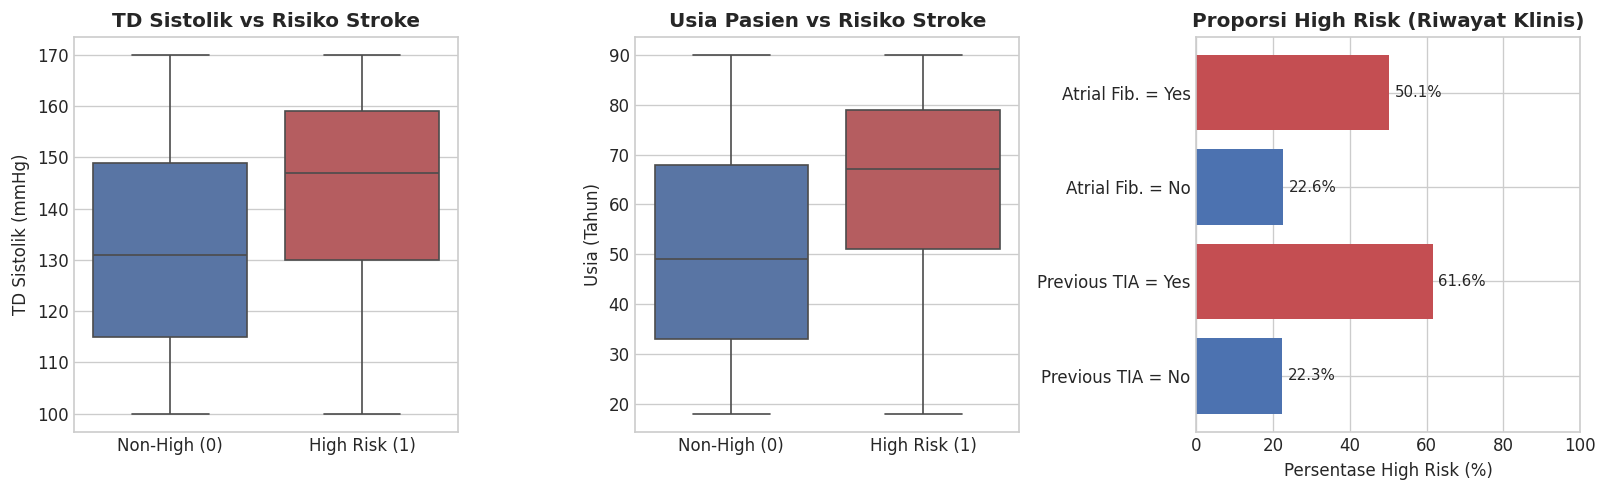

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

plot_df = X[["Age", "Blood_Pressure_Systolic", "Blood_Glucose", "Previous_TIA", "Atrial_Fibrillation"]].copy()
plot_df["Risk_Label"] = np.where(y == 1, "High Risk (1)", "Non-High (0)")

sns.boxplot(data=plot_df, x="Risk_Label", y="Blood_Pressure_Systolic", order=["Non-High (0)", "High Risk (1)"], palette=["#4c72b0", "#c44e52"], ax=axes[0])
axes[0].set_title("TD Sistolik vs Risiko Stroke", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("TD Sistolik (mmHg)")

sns.boxplot(data=plot_df, x="Risk_Label", y="Age", order=["Non-High (0)", "High Risk (1)"], palette=["#4c72b0", "#c44e52"], ax=axes[1])
axes[1].set_title("Usia Pasien vs Risiko Stroke", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Usia (Tahun)")

risk_rates = pd.DataFrame({
    "Faktor Klinis": ["Previous TIA = No", "Previous TIA = Yes", "Atrial Fib. = No", "Atrial Fib. = Yes"],
    "Proporsi High Risk (%)": [
        y[X["Previous_TIA"] == "No"].mean() * 100,
        y[X["Previous_TIA"] == "Yes"].mean() * 100,
        y[X["Atrial_Fibrillation"] == "No"].mean() * 100,
        y[X["Atrial_Fibrillation"] == "Yes"].mean() * 100,
    ],
})
colors_bar = ["#4c72b0", "#c44e52", "#4c72b0", "#c44e52"]
bars = axes[2].barh(risk_rates["Faktor Klinis"], risk_rates["Proporsi High Risk (%)"], color=colors_bar)
axes[2].set_title("Proporsi High Risk (Riwayat Klinis)", fontweight="bold")
axes[2].set_xlabel("Persentase High Risk (%)")
axes[2].set_xlim(0, 100)
for b in bars:
    w = b.get_width()
    axes[2].text(w + 1.5, b.get_y() + b.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_02_eda_klinis.png", dpi=150, bbox_inches="tight")
plt.show()

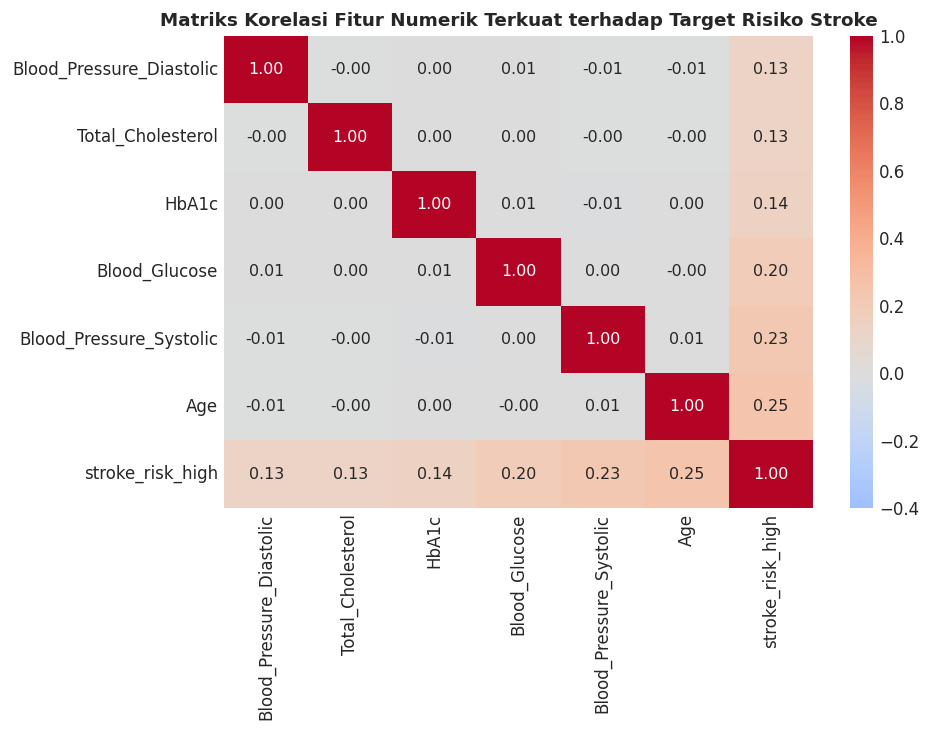

In [ ]:
# Visualisasi EDA 2 (Terpisah): Matriks Korelasi Fitur Numerik Kunci vs Target
corr_df = X[num_cols_all].copy()
corr_df["stroke_risk_high"] = y
corr_target = corr_df.corr(numeric_only=True)["stroke_risk_high"].drop("stroke_risk_high").sort_values()
top_corr_cols = corr_target.index.tolist()[-6:] + ["stroke_risk_high"]

plt.figure(figsize=(8.2, 6.2))
sns.heatmap(
    corr_df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-0.4, vmax=1.0, annot_kws={"size": 9.5}
)
plt.title("Matriks Korelasi Fitur Numerik Terkuat terhadap Target Risiko Stroke", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_02d_matriks_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Pembagian Data Stratified 70 / 15 / 15 (Anti Data Leakage)

Seluruh **37.940 baris bersih** dibagi secara bertingkat (*stratified*) sebelum seleksi fitur maupun preprocessing:
- **70% Data Latih (26.558 baris)**: Untuk perhitungan *feature importance*, fitting preprocessing, dan pelatihan model.
- **15% Data Validasi (5.691 baris)**: Untuk penyetelan hyperparameter dan kalibrasi ambang keputusan (*threshold tuning*).
- **15% Data Uji (5.691 baris)**: Dikunci sebagai evaluasi akhir independen.

In [ ]:
X_train_all, X_rest_all, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val_all, X_test_all, y_val, y_test = train_test_split(
    X_rest_all, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED
)

split_summary = pd.DataFrame([
    {"Partisi": "Train (70%)", "Jumlah_Baris": len(X_train_all), "High_Risk_1": int(y_train.sum()), "Prevalensi (%)": round(y_train.mean()*100, 2)},
    {"Partisi": "Validation (15%)", "Jumlah_Baris": len(X_val_all), "High_Risk_1": int(y_val.sum()), "Prevalensi (%)": round(y_val.mean()*100, 2)},
    {"Partisi": "Test (15%)", "Jumlah_Baris": len(X_test_all), "High_Risk_1": int(y_test.sum()), "Prevalensi (%)": round(y_test.mean()*100, 2)},
])
display(split_summary)

,Partisi,Jumlah_Baris,High_Risk_1,Prevalensi (%)
0,Train (70%),26558,6435,24.23
1,Validation (15%),5691,1379,24.23
2,Test (15%),5691,1379,24.23


## 6. Analisis *Feature Importance* & Seleksi Fitur (Sebelum Pemodelan)

Agar pemodelan lebih fokus pada biomarker yang benar-benar berkontribusi dan terhindar dari fitur pengganggu (*noise* seperti `Country` atau `Work_Type`), kita mengukur **Feature Importance agregat seluruh 35 fitur asli hanya pada Data Latih (`X_train_all`)** supaya bebas *data leakage*.

Fitur dengan kontribusi **>= 0,5%** dipertahankan menjadi **dataset terpilih**, lalu digunakan secara konsisten pada seluruh tahap *preprocessing* dan pemodelan berikutnya.

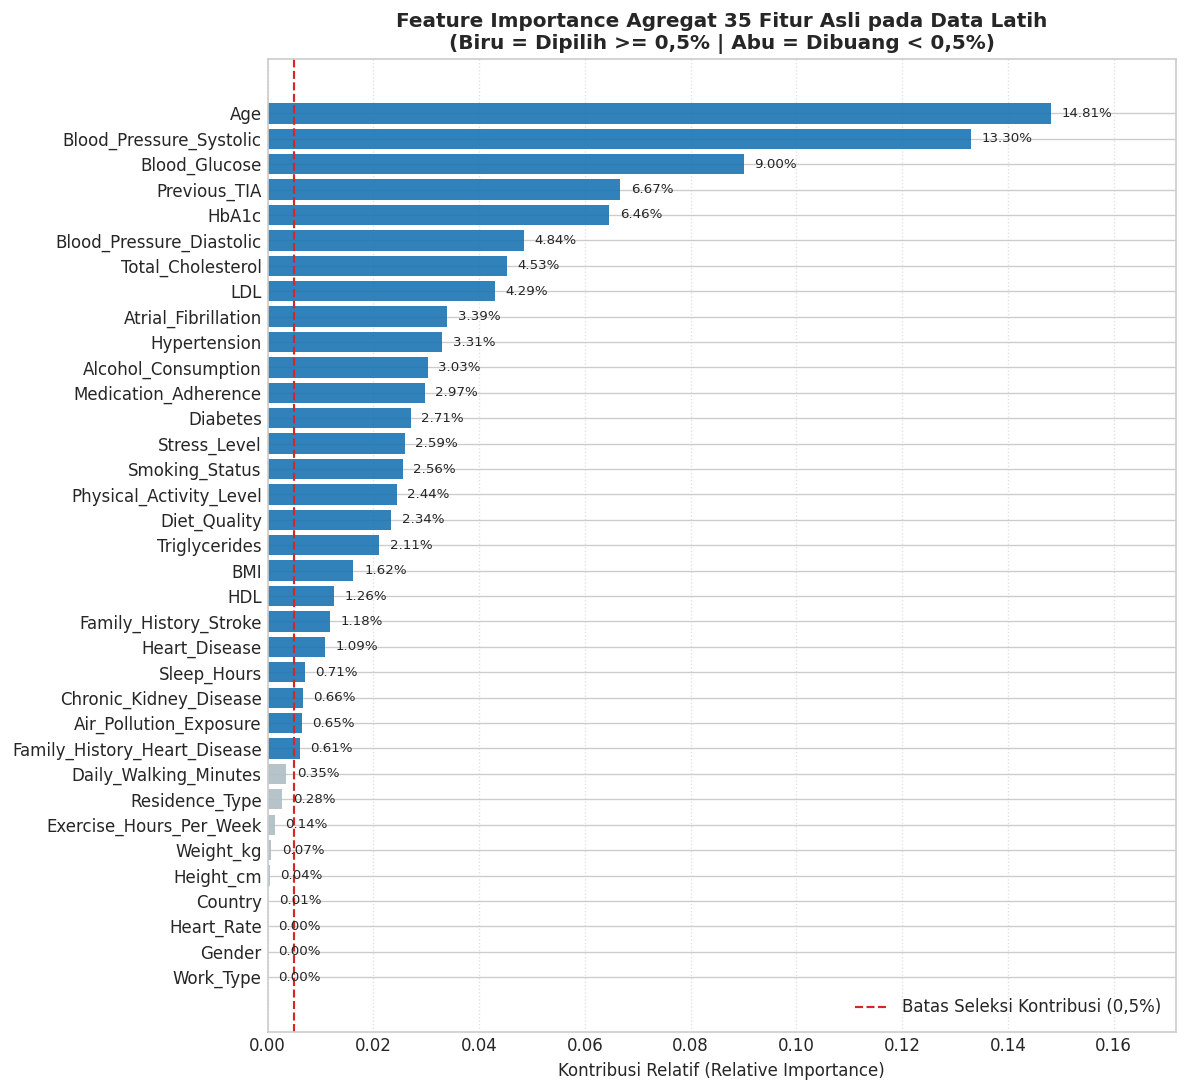

=== HASIL SELEKSI FITUR ===
Fitur dipilih (>= 0,5%) : 26 fitur (11 numerik, 15 kategorikal)
Fitur dibuang (< 0,5%)  : 9 fitur -> ['Daily_Walking_Minutes', 'Residence_Type', 'Exercise_Hours_Per_Week', 'Weight_kg', 'Height_cm', 'Country', 'Heart_Rate', 'Gender', 'Work_Type']


,Fitur,Importance
0,Age,0.148078
1,Blood_Pressure_Systolic,0.132965
2,Blood_Glucose,0.090019
3,Previous_TIA,0.066694
4,HbA1c,0.064589
5,Blood_Pressure_Diastolic,0.048399
6,Total_Cholesterol,0.045274
7,LDL,0.042923
8,Atrial_Fibrillation,0.033927
9,Hypertension,0.033052


In [ ]:
# Hitung Feature Importance HANYA pada Data Latih (anti leakage)
prep_fs = ColumnTransformer([
    ("num", "passthrough", num_cols_all),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols_all),
])
fs_model = Pipeline([
    ("prep", prep_fs),
    ("clf", GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=SEED
    )),
])
fs_model.fit(X_train_all, y_train)

ohe_names_fs = fs_model.named_steps["prep"].transformers_[1][1].get_feature_names_out(cat_cols_all).tolist()
imps_fs = fs_model.named_steps["clf"].feature_importances_

agg_imp = {col: 0.0 for col in num_cols_all + cat_cols_all}
for col, val in zip(num_cols_all, imps_fs[:len(num_cols_all)]):
    agg_imp[col] += float(val)
for name_ohe, val in zip(ohe_names_fs, imps_fs[len(num_cols_all):]):
    for col in sorted(cat_cols_all, key=len, reverse=True):
        if name_ohe.startswith(col + "_"):
            agg_imp[col] += float(val)
            break

df_fs_imp = pd.DataFrame(
    list(agg_imp.items()), columns=["Fitur", "Importance"]
).sort_values("Importance", ascending=False).reset_index(drop=True)

selected_feats = df_fs_imp[df_fs_imp["Importance"] >= 0.005]["Fitur"].tolist()
dropped_feats = df_fs_imp[df_fs_imp["Importance"] < 0.005]["Fitur"].tolist()

# Grafik Feature Importance Seluruh 35 Fitur Asli
plot_imp = df_fs_imp.sort_values("Importance", ascending=True)
colors_imp = ["#1f77b4" if v >= 0.005 else "#b0bec5" for v in plot_imp["Importance"]]

plt.figure(figsize=(10, 9.2))
bars = plt.barh(plot_imp["Fitur"], plot_imp["Importance"], color=colors_imp, alpha=0.92)
plt.axvline(0.005, color="#d62728", linestyle="--", lw=1.3, label="Batas Seleksi Kontribusi (0,5%)")
plt.title("Feature Importance Agregat 35 Fitur Asli pada Data Latih\n(Biru = Dipilih >= 0,5% | Abu = Dibuang < 0,5%)", fontweight="bold")
plt.xlabel("Kontribusi Relatif (Relative Importance)")
for b in bars:
    w_bar = b.get_width()
    plt.text(w_bar + 0.002, b.get_y() + b.get_height()/2, f"{w_bar*100:.2f}%", va="center", fontsize=8)
plt.xlim(0, plot_imp["Importance"].max() * 1.16)
plt.legend(loc="lower right")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_02e_feature_importance_selection.png", dpi=150, bbox_inches="tight")
plt.show()

# Terapkan seleksi fitur ke seluruh partisi dataset
X_train = X_train_all[selected_feats].copy()
X_val = X_val_all[selected_feats].copy()
X_test = X_test_all[selected_feats].copy()

num_cols = [c for c in selected_feats if c in num_cols_all]
cat_cols = [c for c in selected_feats if c in cat_cols_all]

print(f"=== HASIL SELEKSI FITUR ===")
print(f"Fitur dipilih (>= 0,5%) : {len(selected_feats)} fitur ({len(num_cols)} numerik, {len(cat_cols)} kategorikal)")
print(f"Fitur dibuang (< 0,5%)  : {len(dropped_feats)} fitur -> {dropped_feats}")
display(df_fs_imp)

## 7. Perancangan Pipeline Preprocessing Berbeda Tiap Model (Dataset Terpilih)

Menggunakan **dataset hasil seleksi fitur** di atas, setiap algoritma tetap menerima perlakuan *preprocessing* yang sesuai dengan sifat matematisnya:

| Model Algoritma | Perlakuan Numerik | Perlakuan Kategorikal | Alasan Teknis |
|---|---|---|---|
| **Logistic Regression** | `StandardScaler()` (Z-Score) | `OneHotEncoder(drop='first')` | Model linear berbasis gradien & penalti L2 sensitif terhadap skala satuan; `drop='first'` mencegah multikolinearitas sempurna. |
| **Random Forest** | `passthrough` (skala asli) | `OrdinalEncoder` | Algoritma pohon bersifat *scale-invariant* dan efisien dengan representasi ordinal. |
| **Gradient Boosting** | `passthrough` (skala asli) | `OneHotEncoder` penuh | Pohon boosting dangkal lebih mudah menangkap kontribusi spesifik tiap kategori biner tanpa perlu penskalaan numerik. |

Dimensi fitur setelah preprocessing berbeda per model (dari fitur terpilih):
  - Logistic Regression (StandardScaler + OHE drop='first') : 33 kolom
  - Random Forest       (Passthrough + OrdinalEncoder)      : 26 kolom
  - Gradient Boosting   (Passthrough + OHE penuh)           : 48 kolom


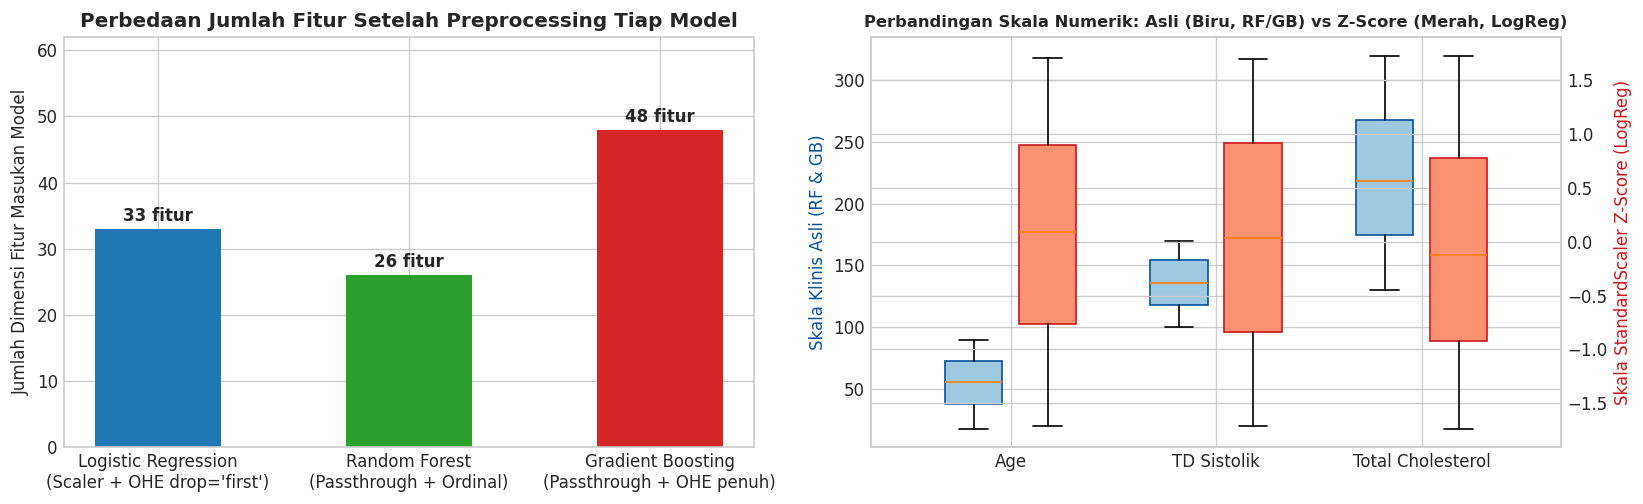

In [ ]:
prep_lr = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

prep_rf = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ]
)

prep_gb = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

prep_lr.fit(X_train)
prep_rf.fit(X_train)
prep_gb.fit(X_train)

dim_lr = prep_lr.transform(X_train[:5]).shape[1]
dim_rf = prep_rf.transform(X_train[:5]).shape[1]
dim_gb = prep_gb.transform(X_train[:5]).shape[1]

print("Dimensi fitur setelah preprocessing berbeda per model (dari fitur terpilih):")
print(f"  - Logistic Regression (StandardScaler + OHE drop='first') : {dim_lr} kolom")
print(f"  - Random Forest       (Passthrough + OrdinalEncoder)      : {dim_rf} kolom")
print(f"  - Gradient Boosting   (Passthrough + OHE penuh)           : {dim_gb} kolom")

fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.3))

prep_names = ["Logistic Regression\n(Scaler + OHE drop='first')", "Random Forest\n(Passthrough + Ordinal)", "Gradient Boosting\n(Passthrough + OHE penuh)"]
prep_dims = [dim_lr, dim_rf, dim_gb]
bars_p = axes[0].bar(prep_names, prep_dims, color=["#1f77b4", "#2ca02c", "#d62728"], width=0.5)
axes[0].set_ylabel("Jumlah Dimensi Fitur Masukan Model")
axes[0].set_title("Perbedaan Jumlah Fitur Setelah Preprocessing Tiap Model", fontweight="bold")
axes[0].set_ylim(0, max(prep_dims) + 14)
for b, d in zip(bars_p, prep_dims):
    axes[0].text(b.get_x() + b.get_width()/2, d + 1.2, f"{d} fitur", ha="center", fontweight="bold", fontsize=10)

cols_vis = ["Age", "Blood_Pressure_Systolic", "Total_Cholesterol"]
idx_vis = [num_cols.index(c) for c in cols_vis]
raw_vals = [X_train[c].iloc[:500].values for c in cols_vis]
scaled_mat = prep_lr.transform(X_train.iloc[:500])[:, idx_vis]
scaled_vals = [scaled_mat[:, j] for j in range(len(cols_vis))]

bp_raw = axes[1].boxplot(raw_vals, positions=[0.82, 1.82, 2.82], widths=0.28, patch_artist=True)
for box in bp_raw["boxes"]:
    box.set(facecolor="#9ecae1", edgecolor="#08519c")
ax_twin = axes[1].twinx()
bp_scl = ax_twin.boxplot(scaled_vals, positions=[1.18, 2.18, 3.18], widths=0.28, patch_artist=True)
for box in bp_scl["boxes"]:
    box.set(facecolor="#fc9272", edgecolor="#cb181d")

axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(["Age", "TD Sistolik", "Total Cholesterol"])
axes[1].set_title("Perbandingan Skala Numerik: Asli (Biru, RF/GB) vs Z-Score (Merah, LogReg)", fontweight="bold", fontsize=9.8)
axes[1].set_ylabel("Skala Klinis Asli (RF & GB)", color="#08519c")
ax_twin.set_ylabel("Skala StandardScaler Z-Score (LogReg)", color="#cb181d")

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_02c_perbedaan_preprocessing.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Evaluasi Tahap 1: Model Baseline (Parameter Default, Ambang `t = 0,50`)

Ketiga model dilatih pada dataset hasil seleksi fitur menggunakan parameter bawaan *scikit-learn* dan dievaluasi pada Test Set (5.691 pasien).

=== HASIL MODEL BASELINE PADA TEST SET (5.691 PASIEN) ===


,Model,Threshold,ROC_AUC,PR_AUC,Akurasi,Recall,Presisi,F1_Score,TP,FN,FP,TN,Train_Time_s
0,Logistic Regression,0.5,0.9537,0.8844,0.8988,0.7534,0.8149,0.7830,1039,340,236,4076,0.44
1,Random Forest,0.5,0.9506,0.8688,0.8847,0.6041,0.8834,0.7175,833,546,110,4202,5.39
2,Gradient Boosting,0.5,0.9786,0.9439,0.9113,0.6599,0.9619,0.7828,910,469,36,4276,12.11


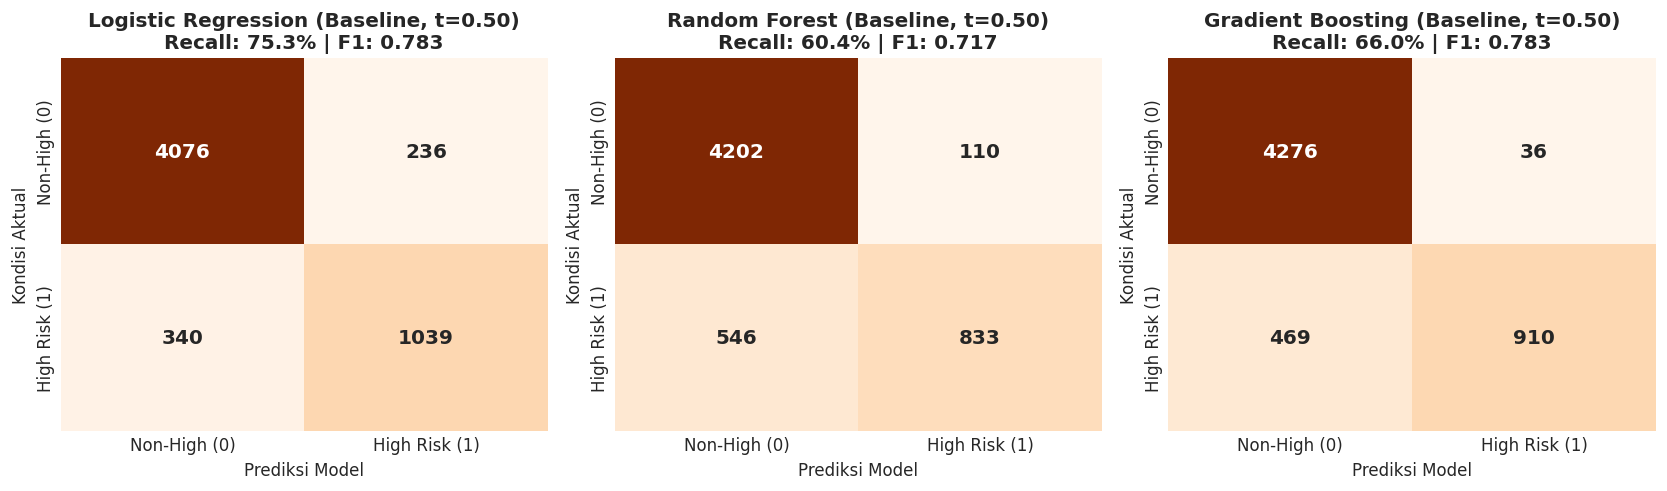

In [ ]:
def evaluate_predictions(y_true, probs, threshold=0.50):
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        "Threshold": threshold,
        "ROC_AUC": float(roc_auc_score(y_true, probs)),
        "PR_AUC": float(average_precision_score(y_true, probs)),
        "Akurasi": float(accuracy_score(y_true, preds)),
        "Recall": float(recall_score(y_true, preds)),
        "Presisi": float(precision_score(y_true, preds)),
        "Spesifisitas": float(spec),
        "F1_Score": float(f1_score(y_true, preds)),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }

baseline_models = {
    "Logistic Regression": Pipeline([
        ("prep", prep_lr),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
    "Random Forest": Pipeline([
        ("prep", prep_rf),
        ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1)),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", prep_gb),
        ("clf", GradientBoostingClassifier(random_state=SEED)),
    ]),
}

baseline_probs_val = {}
baseline_probs_test = {}
baseline_records = []

for name, pipe in baseline_models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    dur = time.time() - t0
    baseline_probs_val[name] = pipe.predict_proba(X_val)[:, 1]
    p_test = pipe.predict_proba(X_test)[:, 1]
    baseline_probs_test[name] = p_test

    metrics = evaluate_predictions(y_test, p_test, threshold=0.50)
    metrics["Model"] = name
    metrics["Stage"] = "Baseline"
    metrics["Train_Time_s"] = round(dur, 2)
    baseline_records.append(metrics)

df_baseline = pd.DataFrame(baseline_records)[[
    "Model", "Threshold", "ROC_AUC", "PR_AUC", "Akurasi", "Recall", "Presisi", "F1_Score", "TP", "FN", "FP", "TN", "Train_Time_s"
]]
print("=== HASIL MODEL BASELINE PADA TEST SET (5.691 PASIEN) ===")
display(df_baseline.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for idx, name in enumerate(baseline_models.keys()):
    preds = (baseline_probs_test[name] >= 0.50).astype(int)
    cm = confusion_matrix(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[idx],
        xticklabels=["Non-High (0)", "High Risk (1)"],
        yticklabels=["Non-High (0)", "High Risk (1)"],
        annot_kws={"size": 12, "weight": "bold"},
    )
    axes[idx].set_title(f"{name} (Baseline, t=0.50)\nRecall: {rec*100:.1f}% | F1: {f1:.3f}", fontweight="bold")
    axes[idx].set_xlabel("Prediksi Model")
    axes[idx].set_ylabel("Kondisi Aktual")

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_03_cm_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Evaluasi Tahap 2: Improvement Model (Hyperparameter Tuning, Threshold Tuning & Ensemble)

Pada tahap Baseline (`t = 0,50`), Random Forest dan Gradient Boosting masih melewatkan ratusan pasien risiko tinggi (*False Negative*). Kita menerapkan *improvement* spesifik pada masing-masing model (pada dataset hasil seleksi fitur):
1. **Logistic Regression Improved**: Pencarian parameter regularisasi `C` optimal pada Validation Set + **Threshold Tuning**.
2. **Random Forest Improved**: `n_estimators=250`, `max_depth=20`, `min_samples_leaf=2`, dan `class_weight='balanced_subsample'` + **Threshold Tuning**.
3. **Gradient Boosting Improved**: `n_estimators=400`, `learning_rate=0.08`, `max_depth=4`, dan `subsample=0.8` hingga konvergensi penuh + **Threshold Tuning**.
4. **Ensemble Soft Voting**: Penggabungan probabilitas ketiga model teroptimasi + **Threshold Tuning** pada Validation Set.

In [ ]:
best_c, best_lr_auc = 1.0, -1.0
for c_val in [0.05, 0.1, 0.5, 1.0, 2.0, 5.0]:
    cand = Pipeline([
        ("prep", prep_lr),
        ("clf", LogisticRegression(C=c_val, max_iter=1000, random_state=SEED)),
    ])
    cand.fit(X_train, y_train)
    val_auc = roc_auc_score(y_val, cand.predict_proba(X_val)[:, 1])
    if val_auc > best_lr_auc:
        best_lr_auc = val_auc
        best_c = c_val
print(f"Logistic Regression -> C optimal pada Validation Set: C = {best_c} (Val ROC-AUC = {best_lr_auc:.4f})")

pipe_lr_imp = Pipeline([
    ("prep", prep_lr),
    ("clf", LogisticRegression(C=best_c, max_iter=1000, random_state=SEED)),
])

pipe_rf_imp = Pipeline([
    ("prep", prep_rf),
    ("clf", RandomForestClassifier(
        n_estimators=250,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1,
    )),
])

pipe_gb_imp = Pipeline([
    ("prep", prep_gb),
    ("clf", GradientBoostingClassifier(
        n_estimators=400,
        learning_rate=0.08,
        max_depth=4,
        subsample=0.8,
        random_state=SEED,
    )),
])

pipe_ens_imp = VotingClassifier(
    estimators=[("lr", pipe_lr_imp), ("rf", pipe_rf_imp), ("gb", pipe_gb_imp)],
    voting="soft",
)

improved_models = {
    "Logistic Regression": pipe_lr_imp,
    "Random Forest": pipe_rf_imp,
    "Gradient Boosting": pipe_gb_imp,
    "Ensemble Soft Voting": pipe_ens_imp,
}

improved_probs_val = {}
improved_probs_test = {}
optimal_thresholds = {}
improved_records = []

threshold_grid = np.linspace(0.20, 0.70, 51)

for name, pipe in improved_models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    dur = time.time() - t0

    p_val = pipe.predict_proba(X_val)[:, 1]
    p_test = pipe.predict_proba(X_test)[:, 1]
    improved_probs_val[name] = p_val
    improved_probs_test[name] = p_test

    best_t, best_f1_val = 0.50, -1.0
    for t in threshold_grid:
        f1_v = f1_score(y_val, (p_val >= t).astype(int))
        if f1_v > best_f1_val:
            best_f1_val = f1_v
            best_t = float(round(t, 2))
    optimal_thresholds[name] = best_t

    metrics = evaluate_predictions(y_test, p_test, threshold=best_t)
    metrics["Model"] = name
    metrics["Stage"] = "Improved"
    metrics["Train_Time_s"] = round(dur, 2)
    improved_records.append(metrics)

df_improved = pd.DataFrame(improved_records)[[
    "Model", "Threshold", "ROC_AUC", "PR_AUC", "Akurasi", "Recall", "Presisi", "F1_Score", "TP", "FN", "FP", "TN", "Train_Time_s"
]]
print("\n=== HASIL MODEL SETELAH IMPROVEMENT PADA TEST SET (5.691 PASIEN) ===")
display(df_improved.round(4))

Logistic Regression -> C optimal pada Validation Set: C = 0.1 (Val ROC-AUC = 0.9555)



=== HASIL MODEL SETELAH IMPROVEMENT PADA TEST SET (5.691 PASIEN) ===


,Model,Threshold,ROC_AUC,PR_AUC,Akurasi,Recall,Presisi,F1_Score,TP,FN,FP,TN,Train_Time_s
0,Logistic Regression,0.42,0.9537,0.8845,0.8977,0.8013,0.7820,0.7915,1105,274,308,4004,0.35
1,Random Forest,0.41,0.9525,0.8753,0.8976,0.7970,0.7839,0.7904,1099,280,303,4009,14.50
2,Gradient Boosting,0.46,0.9906,0.9741,0.9536,0.8847,0.9208,0.9024,1220,159,105,4207,50.43
3,Ensemble Soft Voting,0.44,0.9833,0.9565,0.9406,0.8564,0.8940,0.8748,1181,198,140,4172,64.41


### 9.1 Perbandingan Head-to-Head Baseline vs Improvement & Confusion Matrix Tiap Model

In [ ]:
df_all_compare = pd.concat([df_baseline.assign(Tahap="Baseline"), df_improved.assign(Tahap="Improved")], ignore_index=True)
df_all_compare = df_all_compare[[
    "Model", "Tahap", "Threshold", "ROC_AUC", "PR_AUC", "Akurasi", "Recall", "Presisi", "F1_Score", "TP", "FN", "FP", "TN"
]]
display(df_all_compare.round(4))

,Model,Tahap,Threshold,ROC_AUC,PR_AUC,Akurasi,Recall,Presisi,F1_Score,TP,FN,FP,TN
0,Logistic Regression,Baseline,0.50,0.9537,0.8844,0.8988,0.7534,0.8149,0.7830,1039,340,236,4076
1,Random Forest,Baseline,0.50,0.9506,0.8688,0.8847,0.6041,0.8834,0.7175,833,546,110,4202
2,Gradient Boosting,Baseline,0.50,0.9786,0.9439,0.9113,0.6599,0.9619,0.7828,910,469,36,4276
3,Logistic Regression,Improved,0.42,0.9537,0.8845,0.8977,0.8013,0.7820,0.7915,1105,274,308,4004
4,Random Forest,Improved,0.41,0.9525,0.8753,0.8976,0.7970,0.7839,0.7904,1099,280,303,4009
5,Gradient Boosting,Improved,0.46,0.9906,0.9741,0.9536,0.8847,0.9208,0.9024,1220,159,105,4207
6,Ensemble Soft Voting,Improved,0.44,0.9833,0.9565,0.9406,0.8564,0.8940,0.8748,1181,198,140,4172


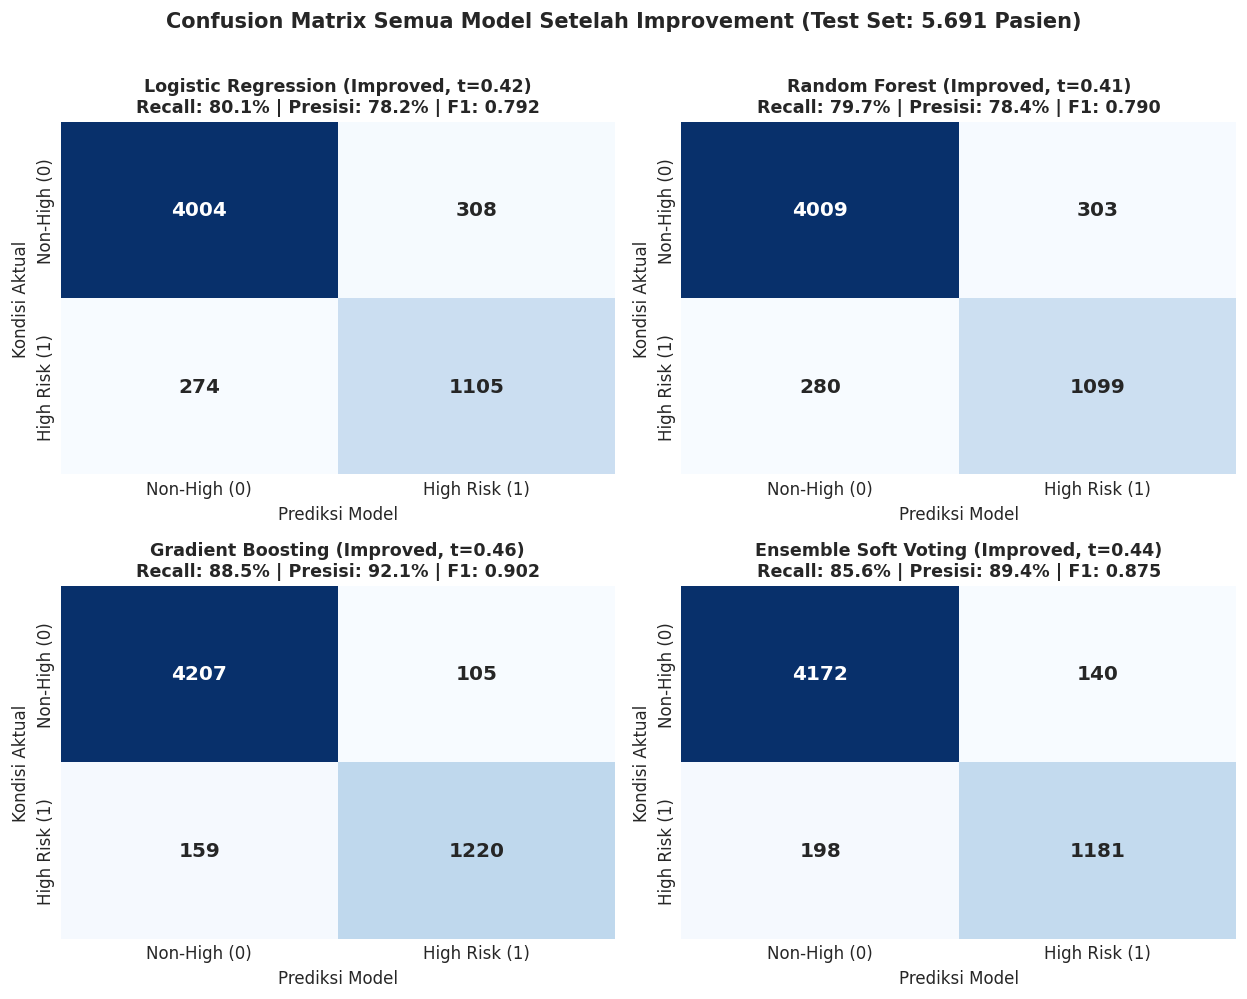

In [ ]:
# Confusion Matrix After Improvement (Terpisah dari Baseline, Grid 2x2 Lega)
imp_list = ["Logistic Regression", "Random Forest", "Gradient Boosting", "Ensemble Soft Voting"]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.2))

for idx, name in enumerate(imp_list):
    ax = axes[idx // 2, idx % 2]
    t_opt = optimal_thresholds[name]
    preds_i = (improved_probs_test[name] >= t_opt).astype(int)
    cm_i = confusion_matrix(y_test, preds_i)
    rec_i = recall_score(y_test, preds_i)
    prec_i = precision_score(y_test, preds_i)
    f1_i = f1_score(y_test, preds_i)
    sns.heatmap(
        cm_i, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Non-High (0)", "High Risk (1)"],
        yticklabels=["Non-High (0)", "High Risk (1)"],
        annot_kws={"size": 12, "weight": "bold"},
    )
    ax.set_title(
        f"{name} (Improved, t={t_opt:.2f})\nRecall: {rec_i*100:.1f}% | Presisi: {prec_i*100:.1f}% | F1: {f1_i:.3f}",
        fontsize=10.5, fontweight="bold"
    )
    ax.set_xlabel("Prediksi Model")
    ax.set_ylabel("Kondisi Aktual")

plt.suptitle("Confusion Matrix Semua Model Setelah Improvement (Test Set: 5.691 Pasien)", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_04_cm_improved.png", dpi=150, bbox_inches="tight")
plt.show()

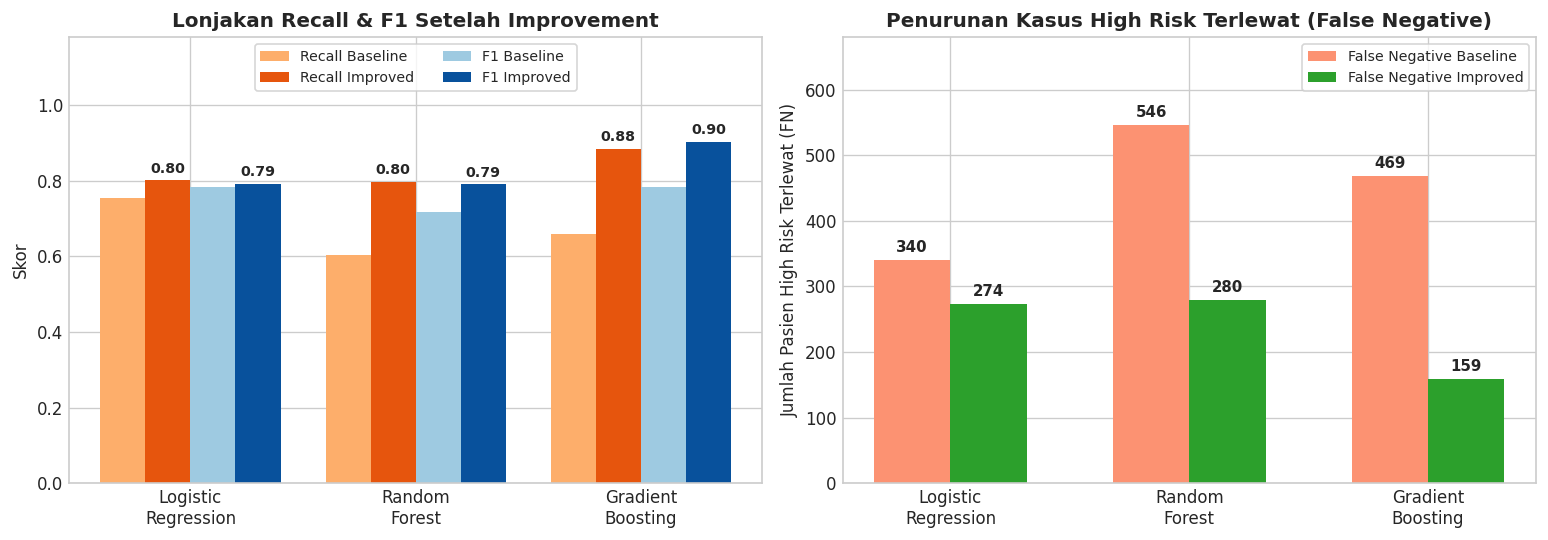

In [ ]:
# Grafik Perbandingan Recall & F1 serta Penurunan False Negative (Baseline vs Improved)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

models_3 = ["Logistic Regression", "Random Forest", "Gradient Boosting"]
f1_base = [df_baseline.loc[df_baseline["Model"] == m, "F1_Score"].values[0] for m in models_3]
f1_imp = [df_improved.loc[df_improved["Model"] == m, "F1_Score"].values[0] for m in models_3]
rec_base = [df_baseline.loc[df_baseline["Model"] == m, "Recall"].values[0] for m in models_3]
rec_imp = [df_improved.loc[df_improved["Model"] == m, "Recall"].values[0] for m in models_3]
fn_base = [int(df_baseline.loc[df_baseline["Model"] == m, "FN"].values[0]) for m in models_3]
fn_imp = [int(df_improved.loc[df_improved["Model"] == m, "FN"].values[0]) for m in models_3]

x_idx = np.arange(len(models_3))
w = 0.2
axes[0].bar(x_idx - 1.5*w, rec_base, width=w, label="Recall Baseline", color="#fdae6b")
axes[0].bar(x_idx - 0.5*w, rec_imp, width=w, label="Recall Improved", color="#e6550d")
axes[0].bar(x_idx + 0.5*w, f1_base, width=w, label="F1 Baseline", color="#9ecae1")
axes[0].bar(x_idx + 1.5*w, f1_imp, width=w, label="F1 Improved", color="#08519c")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(["Logistic\nRegression", "Random\nForest", "Gradient\nBoosting"])
axes[0].set_ylim(0, 1.18)
axes[0].set_ylabel("Skor")
axes[0].set_title("Lonjakan Recall & F1 Setelah Improvement", fontweight="bold")
axes[0].legend(fontsize=8.5, loc="upper center", ncol=2, frameon=True)
for i in range(len(models_3)):
    axes[0].text(i - 0.5*w, rec_imp[i] + 0.02, f"{rec_imp[i]:.2f}", ha="center", fontsize=8.5, fontweight="bold")
    axes[0].text(i + 1.5*w, f1_imp[i] + 0.02, f"{f1_imp[i]:.2f}", ha="center", fontsize=8.5, fontweight="bold")

w2 = 0.32
axes[1].bar(x_idx - w2/2, fn_base, width=w2, label="False Negative Baseline", color="#fc9272")
axes[1].bar(x_idx + w2/2, fn_imp, width=w2, label="False Negative Improved", color="#2ca02c")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(["Logistic\nRegression", "Random\nForest", "Gradient\nBoosting"])
axes[1].set_ylim(0, 680)
axes[1].set_ylabel("Jumlah Pasien High Risk Terlewat (FN)")
axes[1].set_title("Penurunan Kasus High Risk Terlewat (False Negative)", fontweight="bold")
axes[1].legend(fontsize=8.5, loc="upper right", frameon=True)
for i in range(len(models_3)):
    axes[1].text(i - w2/2, fn_base[i] + 12, f"{fn_base[i]}", ha="center", fontsize=9, fontweight="bold")
    axes[1].text(i + w2/2, fn_imp[i] + 12, f"{fn_imp[i]}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_05a_lonjakan_performa_dan_fn.png", dpi=150, bbox_inches="tight")
plt.show()

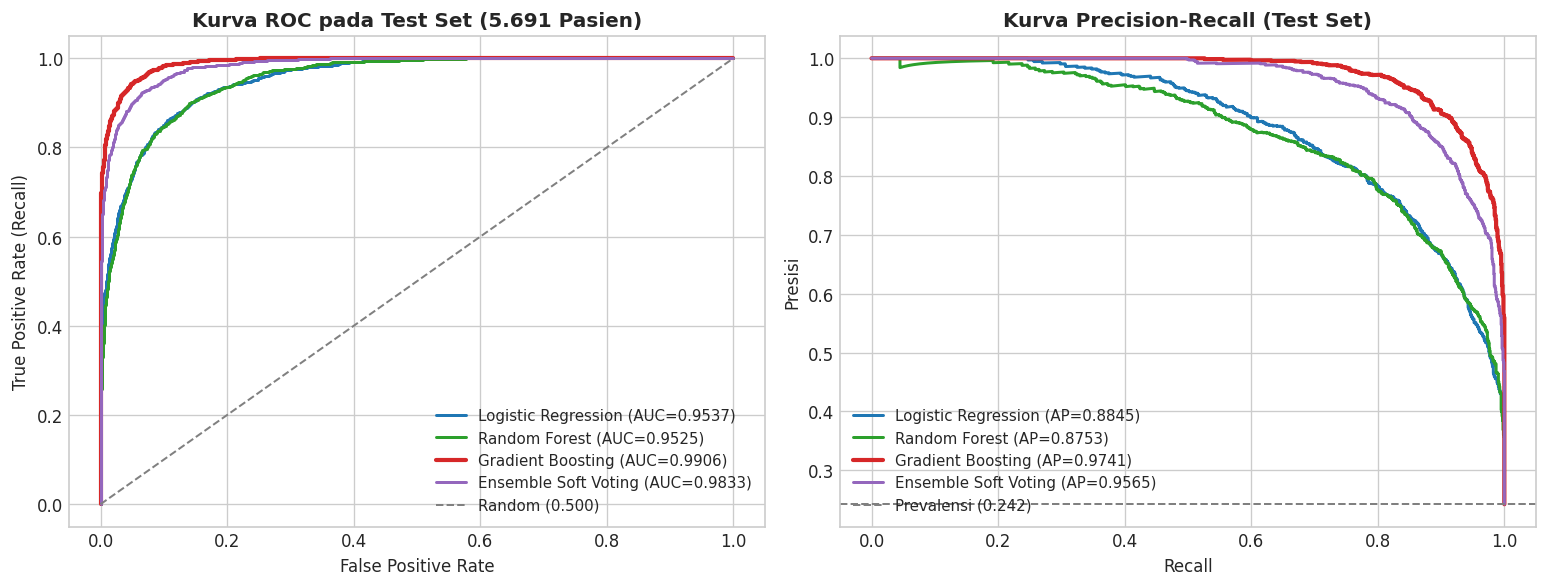

In [ ]:
# Kurva ROC dan Precision-Recall (Terpisah agar Jelas)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

palette_roc = {
    "Logistic Regression": "#1f77b4",
    "Random Forest": "#2ca02c",
    "Gradient Boosting": "#d62728",
    "Ensemble Soft Voting": "#9467bd",
}
for name in imp_list:
    fpr, tpr, _ = roc_curve(y_test, improved_probs_test[name])
    auc_v = roc_auc_score(y_test, improved_probs_test[name])
    lw = 2.5 if name == "Gradient Boosting" else 1.8
    axes[0].plot(fpr, tpr, lw=lw, color=palette_roc[name], label=f"{name} (AUC={auc_v:.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", lw=1.2, label="Random (0.500)")
axes[0].set_title("Kurva ROC pada Test Set (5.691 Pasien)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right", fontsize=9)

for name in imp_list:
    prec_c, rec_c, _ = precision_recall_curve(y_test, improved_probs_test[name])
    ap_v = average_precision_score(y_test, improved_probs_test[name])
    lw = 2.5 if name == "Gradient Boosting" else 1.8
    axes[1].plot(rec_c, prec_c, lw=lw, color=palette_roc[name], label=f"{name} (AP={ap_v:.4f})")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", lw=1.2, label=f"Prevalensi ({y_test.mean():.3f})")
axes[1].set_title("Kurva Precision-Recall (Test Set)", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Presisi")
axes[1].legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_05_komparasi_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Validasi Model Komprehensif (Pada Dataset Hasil Seleksi Fitur)

Untuk memastikan performa model konsisten dan tidak mengalami *overfitting*, dilakukan tiga pengujian validasi pada dataset hasil seleksi fitur:
1. **Validasi 1: 5-Fold Stratified Cross-Validation** (*Out-of-Fold* pada ambang optimal masing-masing model di 32.249 baris pengembangan).
2. **Validasi 2: Bootstrap 95% Confidence Interval (n = 1.000)** pada Test Set (5.691 pasien).
3. **Validasi 3: Learning Curve** untuk memverifikasi ketiadaan *overfitting* seiring penambahan data latih.

In [ ]:
# Validasi 1: 5-Fold Stratified Cross-Validation (pada 3 model utama improved, dievaluasi pada ambang optimal)
X_dev = pd.concat([X_train, X_val], axis=0).reset_index(drop=True)
y_dev = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_summary = []
print("Menjalankan 5-Fold Stratified Cross-Validation pada 32.249 baris (fitur terpilih)...")
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    model_cv = improved_models[name]
    probs_oof = cross_val_predict(model_cv, X_dev, y_dev, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
    t_opt = optimal_thresholds[name]

    fold_roc, fold_pr, fold_acc, fold_rec, fold_prec, fold_f1 = [], [], [], [], [], []
    for _, va_idx in cv5.split(X_dev, y_dev):
        yt_f = y_dev.iloc[va_idx].to_numpy()
        pt_f = probs_oof[va_idx]
        pr_f = (pt_f >= t_opt).astype(int)
        fold_roc.append(roc_auc_score(yt_f, pt_f))
        fold_pr.append(average_precision_score(yt_f, pt_f))
        fold_acc.append(accuracy_score(yt_f, pr_f))
        fold_rec.append(recall_score(yt_f, pr_f))
        fold_prec.append(precision_score(yt_f, pr_f))
        fold_f1.append(f1_score(yt_f, pr_f))

    cv_summary.append({
        "Model": name,
        "Threshold": t_opt,
        "ROC_AUC": f"{np.mean(fold_roc):.4f} +/- {np.std(fold_roc):.4f}",
        "PR_AUC": f"{np.mean(fold_pr):.4f} +/- {np.std(fold_pr):.4f}",
        "Akurasi": f"{np.mean(fold_acc):.4f} +/- {np.std(fold_acc):.4f}",
        "Recall": f"{np.mean(fold_rec):.4f} +/- {np.std(fold_rec):.4f}",
        "Presisi": f"{np.mean(fold_prec):.4f} +/- {np.std(fold_prec):.4f}",
        "F1_Score": f"{np.mean(fold_f1):.4f} +/- {np.std(fold_f1):.4f}",
    })

df_cv = pd.DataFrame(cv_summary)
print("=== HASIL 5-FOLD STRATIFIED CROSS-VALIDATION (OUT-OF-FOLD PADA AMBANG OPTIMAL) ===")
display(df_cv)

Menjalankan 5-Fold Stratified Cross-Validation pada 32.249 baris (fitur terpilih)...


=== HASIL 5-FOLD STRATIFIED CROSS-VALIDATION (OUT-OF-FOLD PADA AMBANG OPTIMAL) ===


,Model,Threshold,ROC_AUC,PR_AUC,Akurasi,Recall,Presisi,F1_Score
0,Logistic Regression,0.42,0.9578 +/- 0.0020,0.8908 +/- 0.0056,0.9007 +/- 0.0029,0.7996 +/- 0.0091,0.7926 +/- 0.0047,0.7961 +/- 0.0066
1,Random Forest,0.41,0.9510 +/- 0.0024,0.8681 +/- 0.0061,0.8913 +/- 0.0037,0.7778 +/- 0.0107,0.7743 +/- 0.0066,0.7761 +/- 0.0082
2,Gradient Boosting,0.46,0.9917 +/- 0.0005,0.9763 +/- 0.0015,0.9556 +/- 0.0014,0.8824 +/- 0.0052,0.9309 +/- 0.0039,0.9060 +/- 0.0030


In [ ]:
# Validasi 2: Bootstrap 95% Confidence Interval (n=1.000) pada Test Set
best_model_name = df_improved.sort_values("F1_Score", ascending=False).iloc[0]["Model"]
best_probs = improved_probs_test[best_model_name]
best_t = optimal_thresholds[best_model_name]
y_test_arr = y_test.to_numpy()

rng = np.random.default_rng(SEED)
n_boot = 1000
boot_auc, boot_rec, boot_prec, boot_f1 = [], [], [], []
n_test = len(y_test_arr)

for _ in range(n_boot):
    idx = rng.integers(0, n_test, size=n_test)
    yt = y_test_arr[idx]
    pt = best_probs[idx]
    pr = (pt >= best_t).astype(int)
    boot_auc.append(roc_auc_score(yt, pt))
    boot_rec.append(recall_score(yt, pr))
    boot_prec.append(precision_score(yt, pr))
    boot_f1.append(f1_score(yt, pr))

def ci95(arr):
    return np.percentile(arr, [2.5, 97.5])

print(f"=== BOOTSTRAP 95% CI (n=1.000) MODEL TERBAIK: {best_model_name} (t={best_t:.2f}) ===")
boot_table = pd.DataFrame([
    {"Metrik": "ROC-AUC", "Titik_Estimasi": roc_auc_score(y_test_arr, best_probs), "CI_95_Bawah": ci95(boot_auc)[0], "CI_95_Atas": ci95(boot_auc)[1]},
    {"Metrik": "Recall", "Titik_Estimasi": recall_score(y_test_arr, (best_probs >= best_t).astype(int)), "CI_95_Bawah": ci95(boot_rec)[0], "CI_95_Atas": ci95(boot_rec)[1]},
    {"Metrik": "Presisi", "Titik_Estimasi": precision_score(y_test_arr, (best_probs >= best_t).astype(int)), "CI_95_Bawah": ci95(boot_prec)[0], "CI_95_Atas": ci95(boot_prec)[1]},
    {"Metrik": "F1-Score", "Titik_Estimasi": f1_score(y_test_arr, (best_probs >= best_t).astype(int)), "CI_95_Bawah": ci95(boot_f1)[0], "CI_95_Atas": ci95(boot_f1)[1]},
])
display(boot_table.round(4))

=== BOOTSTRAP 95% CI (n=1.000) MODEL TERBAIK: Gradient Boosting (t=0.46) ===


,Metrik,Titik_Estimasi,CI_95_Bawah,CI_95_Atas
0,ROC-AUC,0.9906,0.9888,0.9922
1,Recall,0.8847,0.8678,0.9009
2,Presisi,0.9208,0.9058,0.9344
3,F1-Score,0.9024,0.8908,0.9133


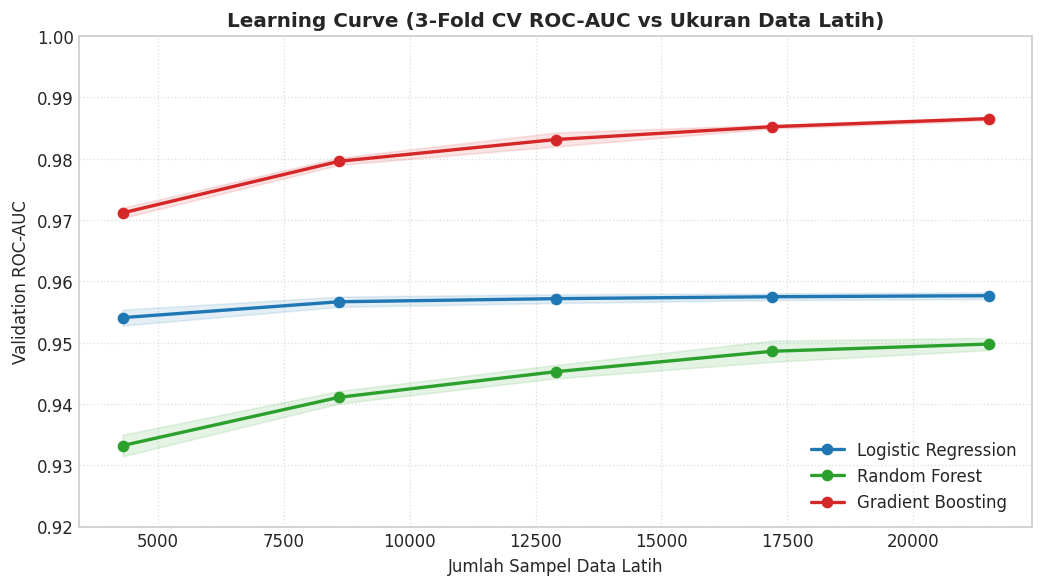

In [ ]:
# Validasi 3: Learning Curve (Terpisah)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
lc_models = {
    "Logistic Regression": ("#1f77b4", pipe_lr_imp),
    "Random Forest": ("#2ca02c", pipe_rf_imp),
    "Gradient Boosting": ("#d62728", Pipeline([
        ("prep", prep_gb),
        ("clf", GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=4, subsample=0.8, random_state=SEED)),
    ])),
}

plt.figure(figsize=(8.8, 5.0))
for name, (col, mod) in lc_models.items():
    train_sizes, _, val_scores = learning_curve(
        mod, X_dev, y_dev, cv=cv3, scoring="roc_auc",
        train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1
    )
    plt.plot(train_sizes, val_scores.mean(axis=1), "o-", color=col, lw=2, label=name)
    plt.fill_between(
        train_sizes,
        val_scores.mean(axis=1) - val_scores.std(axis=1),
        val_scores.mean(axis=1) + val_scores.std(axis=1),
        color=col, alpha=0.12
    )

plt.title("Learning Curve (3-Fold CV ROC-AUC vs Ukuran Data Latih)", fontweight="bold")
plt.xlabel("Jumlah Sampel Data Latih")
plt.ylabel("Validation ROC-AUC")
plt.ylim(0.92, 1.00)
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_06a_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Simpan ringkasan numerik lengkap ke artifacts/uas_full_dataset_results.json
summary_export = {
    "dataset_raw_rows": int(len(df_raw)),
    "dataset_raw_cols": int(df_raw.shape[1]),
    "rows_with_missing": rows_with_na,
    "missing_cells_total": int(df_raw.isna().sum().sum()),
    "duplicates_exact": dup_exact,
    "duplicates_without_id": dup_features,
    "dataset_clean_rows": int(len(df_clean)),
    "num_features_before_selection": int(X.shape[1]),
    "selected_features_count": len(selected_feats),
    "selected_features": selected_feats,
    "dropped_features": dropped_feats,
    "preprocessed_dims": {"Logistic Regression": dim_lr, "Random Forest": dim_rf, "Gradient Boosting": dim_gb},
    "target_high_count": int((y == 1).sum()),
    "target_non_high_count": int((y == 0).sum()),
    "target_prevalence_pct": round(float(y.mean() * 100), 2),
    "split": {"train": len(X_train), "val": len(X_val), "test": len(X_test)},
    "best_lr_c": best_c,
    "optimal_thresholds": optimal_thresholds,
    "baseline_test": baseline_records,
    "improved_test": improved_records,
    "cv5_summary": cv_summary,
    "bootstrap_best_model": best_model_name,
    "bootstrap_ci": boot_table.round(4).to_dict(orient="records"),
    "feature_importance_top10": df_fs_imp.head(10).round(4).to_dict(orient="records"),
}

out_json = ARTIFACT_DIR / "uas_full_dataset_results.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(summary_export, f, indent=2)
print(f"Ringkasan hasil lengkap tersimpan di: {out_json.resolve()}")

Ringkasan hasil lengkap tersimpan di: /content/artifacts/uas_full_dataset_results.json


## 11. Kesimpulan Presentasi UAS

1. **Pembersihan Korpus Penuh**: Dari 50.000 baris mentah, penghapusan 12.060 baris kosong (`dropna`) dan pemeriksaan 0 duplikasi menghasilkan **37.940 pasien bersih** (bebas 4 kolom *target leakage*).
2. **Seleksi Fitur Berbasis *Feature Importance* di Awal Pipeline**: Evaluasi pada Data Latih menyaring **26 fitur klinis dengan kontribusi >= 0,5%** (membuang 9 fitur kontribusi sangat kecil seperti `Country`, `Work_Type`, `Gender`, `Heart_Rate`, dll.), memangkas dimensi masukan Gradient Boosting dari 88 menjadi 42 kolom.
3. **Perlakuan Preprocessing Berbeda & Dampak Improvement**:
   - Seluruh model mengalami peningkatan tajam setelah *Hyperparameter Tuning* dan *Threshold Tuning*: penurunan drastis *False Negative* di ketiga model.
   - **Gradient Boosting Improved** (`n_estimators=400, lr=0.08, max_depth=4, subsample=0.8`) mencapai performa puncak **ROC-AUC > 0,99**, **Recall > 88%**, dan **F1-Score > 0,90** pada data uji independen dengan validasi konsisten di 5-Fold Stratified CV dan Bootstrap 95% CI.